# ANA-068 — Adaptive walks, accessibility and neutral connectivity

**GB1 and TrpB · EXP-066 / RUN-172.** Reuse the frozen production fits to compare
whole measured single-amino-acid-substitution graphs with their synthetic counterparts.
This analysis adds dynamics and network structure to ANA-067's aggregate statistics.
It does not fit new parameters or test ML policies. Historical ANA-020 analysed an
older model; ANA-063/064 measured paths and neutral edges on small cubes.

The four-site spaces contain at most 160,000 genotypes and 6,080,000 undirected
edges, making exact graph calculations tractable. The model is always masked to
the same finite measured genotypes as its empirical comparison.

Run all cells to recompute all graph calculations and figures. A C++17 compiler
is required (macOS Command Line Tools or Linux g++); the small graph kernel is
compiled into a temporary directory. Python dependencies are pinned alongside
this notebook. See `../protocol.md` for the analysis plan.

In [1]:
from pathlib import Path
import sys, json, time
from IPython.display import display
%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'labproject.yaml').exists())
ANA = ROOT/'analyses/2026-10-08_ANA-068_gb1-trpb-adaptive-walks-accessibility-neutral-networks'
sys.path.insert(0,str(ANA/'notebooks'))
import analysis_tools as tools
import plot_tools as plots
print('Data:', tools.DATA)
print('Independent kernel validation:', tools.validate_kernel())

Data: /Users/matthewspence/Documents/Documents/project-adapt-env/data/processed/production_landscapes/ANA-068
Independent kernel validation: {'small_graph_cases': 20, 'independent_checks': ['recursive walk moments', 'exhaustive reachability', 'SciPy components', 'degrees'], 'kernel_sha256': '152e75c7add7876e09ca9e82d24e2b7f2b176e099910fd8ff3593ccc8df0bf75'}


## Recompute the frozen comparisons

Sixteen existing confirmation landscape seeds are retained. GB1 uses r=4 and r=0
sigmoid fits. TrpB additionally uses r=4 independent-difference and shared-stop
calibrations, with intrinsic and observed maps kept separate. Observations are
**drawn once per genotype**, not redrawn whenever a walk revisits a sequence.

Dynamic programming gives exact expectations under uniform uphill and greedy
walks from every valid start. Reachability includes indirect paths and reversions.
The upper 1% target includes all fitness ties at its boundary; the best target is
the whole best measured-fitness plateau. Their realized sizes are reported.

This whole-library assessment includes calibration genotypes and noise donors.
Parameters are frozen, but the results are descriptive post-fit comparisons, not
an entirely new independent confirmation test. Computational assertions concern
mathematical identities and provenance, not scientific acceptance gates.

In [2]:
started = time.perf_counter()
frames = tools.calculate()
print(f'Whole analysis completed in {time.perf_counter()-started:.1f} seconds')
display(frames['coverage'])
audit = json.loads((tools.DATA/'audit.json').read_text())
display({k:v for k,v in audit.items() if k not in ['manifest','source','inputs']})

GB1 empirical -1 finished


GB1 r4_none 660542155 finished


GB1 r0_none 660542155 finished


GB1 r4_none 660542156 finished


GB1 r0_none 660542156 finished


GB1 r4_none 660542157 finished


... (123 outputs left out)

TrpB r4_shared_observed 57117809 finished


Whole analysis completed in 139.1 seconds


,protein,nodes,possible_nodes,edges,complete_neighbourhood_fraction,mean_degree,calibration_origin,calibration_scale,near_floor_cutoff
0,GB1,149361,160000,5492805,0.180783,73.550726,0.000000,2.895682,0.000000
1,TrpB,159129,160000,6016433,0.819474,75.617053,-0.035223,0.193969,0.053832


{'frozen_fits_sha256': 'cc4b36b007b0a5b9b3c4521b873dbebb31e80f05a7841e08927dad271f092d37',
 'noise_donors_sha256': '3030e184e7639c7737ed61dee17d3097a22a4b93737331c2b50822e659233db1',
 'analysis_kernel_sha256': '152e75c7add7876e09ca9e82d24e2b7f2b176e099910fd8ff3593ccc8df0bf75',
 'calculation_source_sha256': '60e31edefe44d4e486e220cd4887387ba8930f1adf91c3cfcc395bae2c3b0ec7',
 'protocol_sha256': '1d948ab4d90d2901dee790b4fea4de9307b58aae33dabd1f5eb02a56c9d94fec',
 'python_version': '3.13.11',
 'numpy_version': '2.4.4',
 'pandas_version': '2.3.0',
 'elapsed_seconds': 138.70481479197042,
 'landscapes': 130,
 'graph_diagnostics': 390,
 'replayed_latent_nodes': 4096,
 'kernel_validation': {'small_graph_cases': 20,
  'independent_checks': ['recursive walk moments',
   'exhaustive reachability',
   'SciPy components',
   'degrees'],
  'kernel_sha256': '152e75c7add7876e09ca9e82d24e2b7f2b176e099910fd8ff3593ccc8df0bf75'},
 'walks_per_policy_landscape': 2048,
 'walk_step_cap': 128,
 'all_walks_termi

## Figure 1 — Adaptive trajectories

Uniform uphill walks choose uniformly among beneficial neighbours; greedy walks
choose the largest available fitness, breaking exact ties uniformly. Neither
rule asserts a specific effective population size or mutation rate. The x-axis
counts accepted substitutions, not time. Walks start uniformly over measured
nodes and remain at their terminal point after absorption.

Fitness uses the empirical calibration origin and range, so the plot preserves
absolute readout-scale differences. Shading is variation across 16 synthetic
seeds (10th–90th percentiles), not a confidence interval for biological truth.

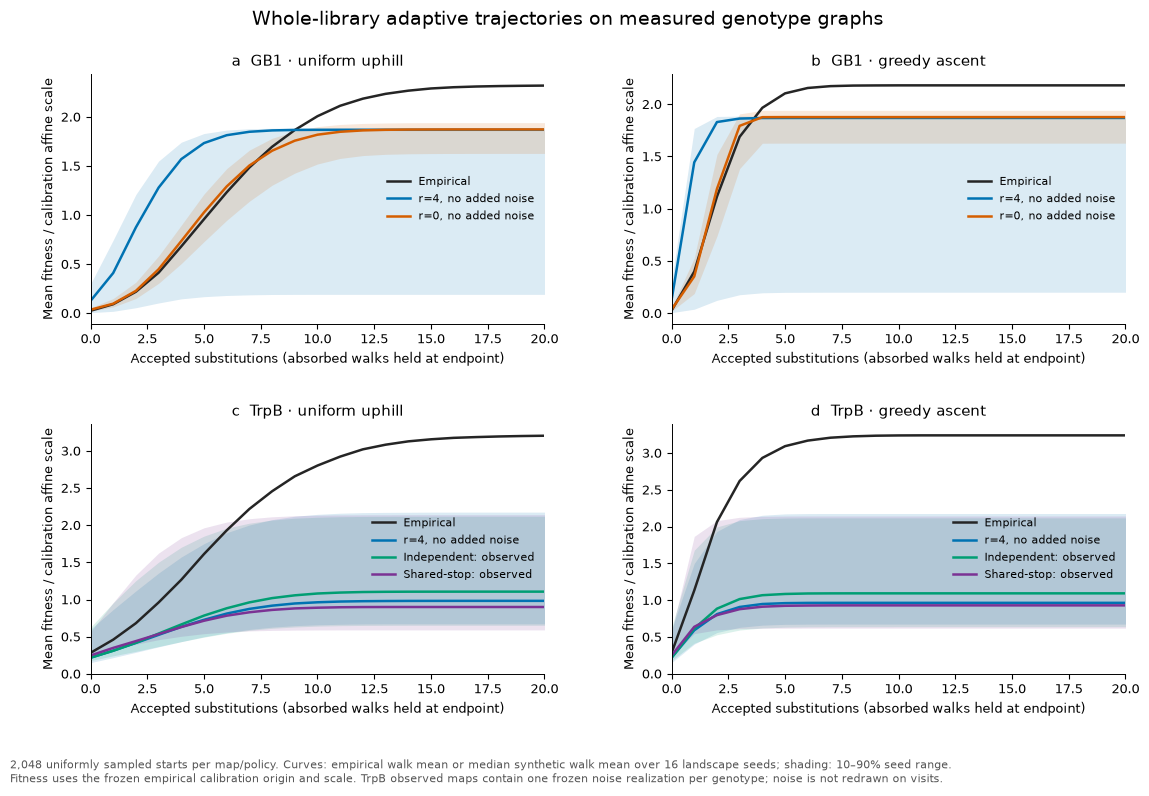

In [3]:
plots.trajectories(frames)

## Figure 2 — Where do walks finish?

Ranks are measured within each landscape, with midranks for ties. Similar endpoint
ranks need not imply similar absolute fitness. The empirical curve is conditional
on the measured map, and each map contributes 2,048 walks per policy.

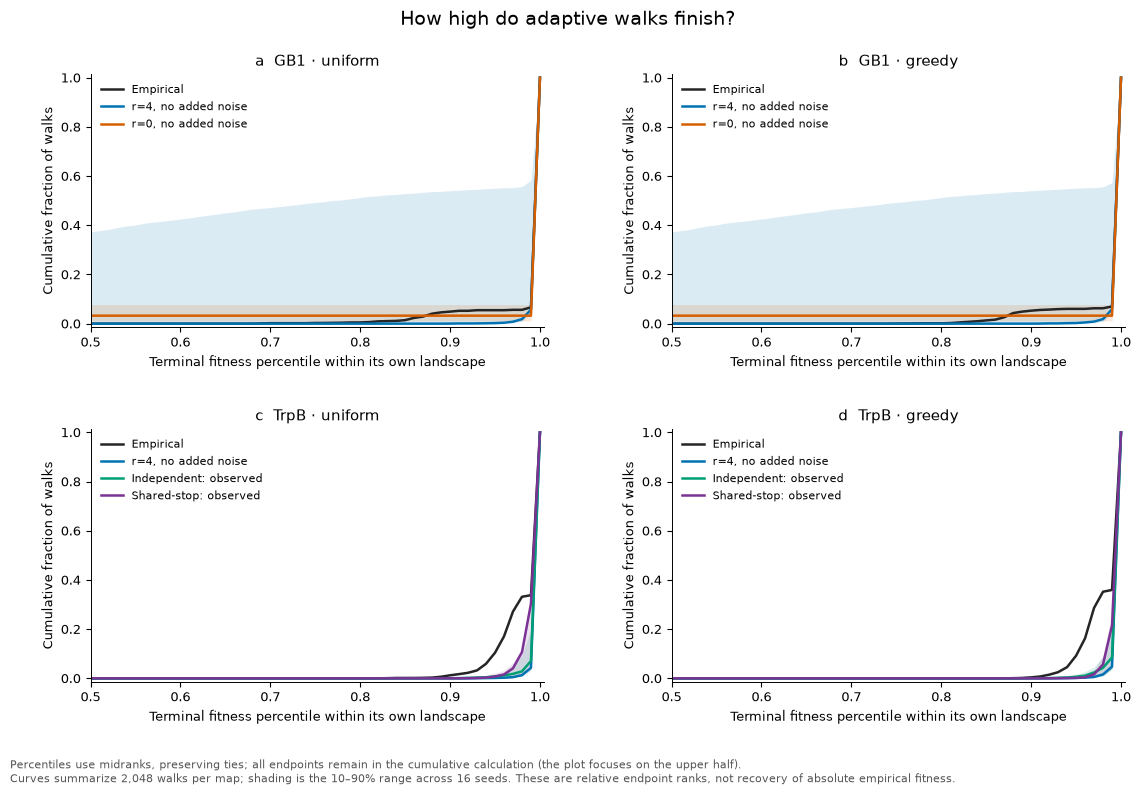

In [4]:
plots.endpoints(frames)

## Figure 3 — Accessibility is not the same as probability of success

A genotype can have a beneficial route to a target even if most adaptive walks
terminate elsewhere. These are exact reachability fractions and walk probabilities
on the measured graph. No path-length cap is applied to the dynamic programming.
The displayed target sets include ties and are specific to each landscape.

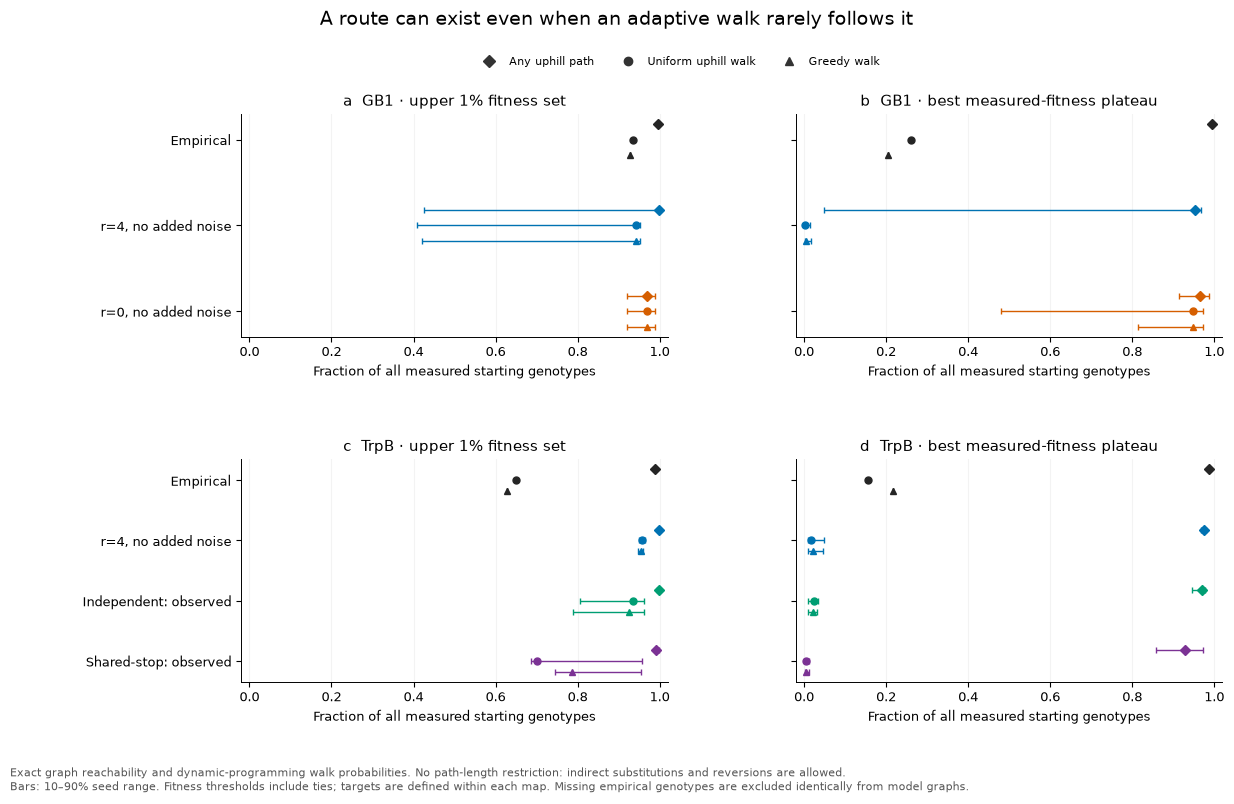

In [5]:
plots.accessibility(frames)

## Figure 4 — Neutral networks require a stated definition

Here an edge is near-neutral when |Δfitness| ≤ epsilon. We examine exact ties and
tolerances of 0.001 and 0.01 times the empirical calibration range. These choices
are sensitivity scales, not experimentally identified selection thresholds.

Connected near-neutral edges can **chain across a broad fitness range**. A large
component is therefore not automatically one molecular phenotype or one fitness
plateau. We separately analyse the induced above-floor subset: GB1 >0, TrpB >0.05383.
These frozen assay cutoffs do not establish biological viability.

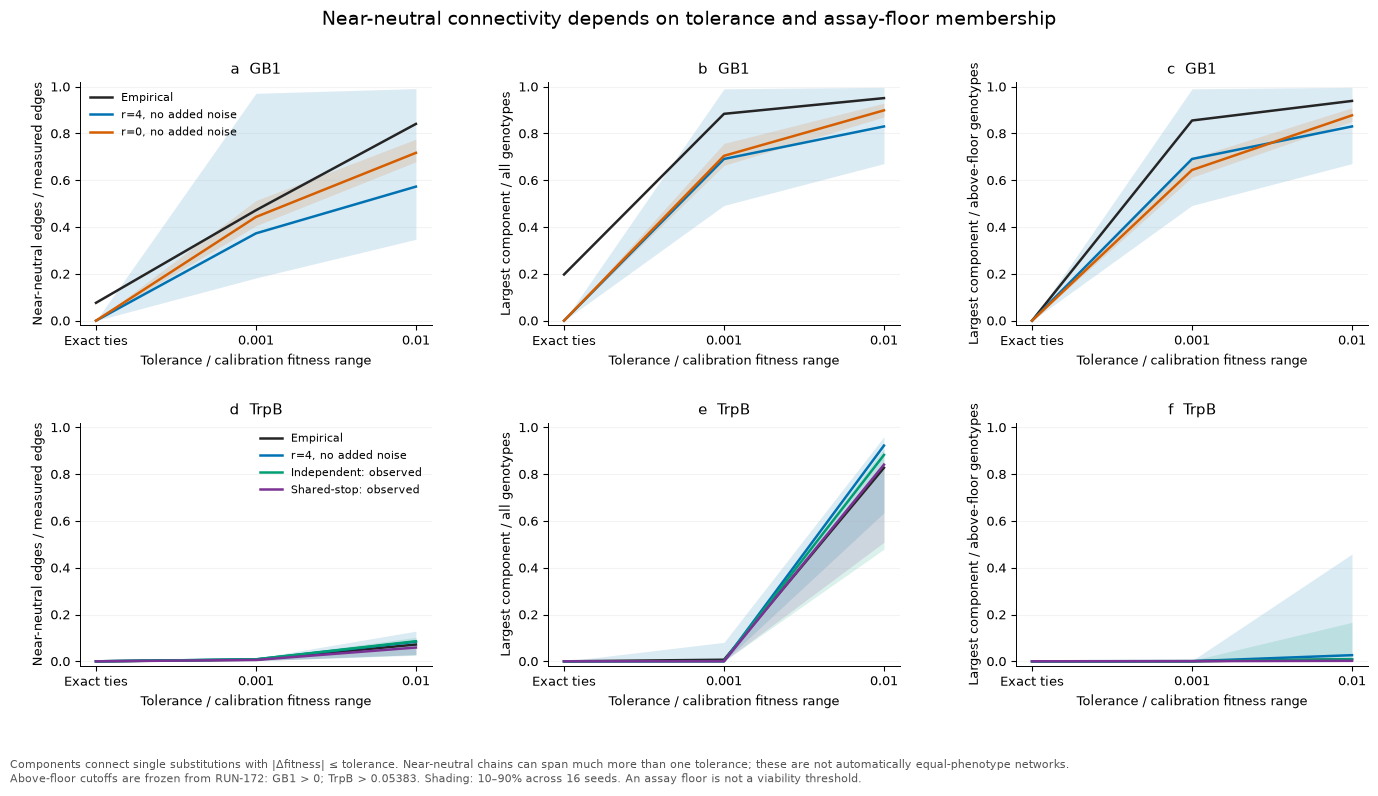

In [6]:
plots.neutrality(frames)

## Figure 5 — Observation can change the apparent search landscape

Compare matched intrinsic and observed maps under each TrpB noise assumption.
The noise model is reused from RUN-172. Its effect on topology is itself an
analysis result; it is not proof of the true intrinsic biological topology.

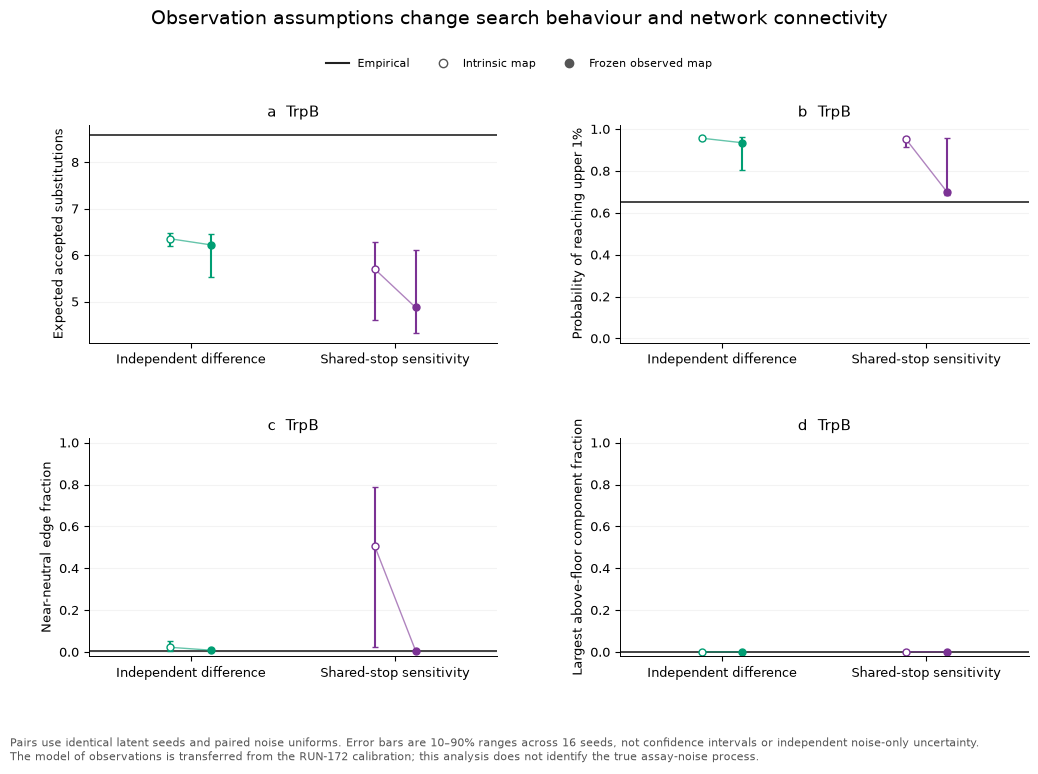

In [7]:
plots.observation(frames)

## Figure 6 — Missingness and neutrality diagnostics

Removing unmeasured genotypes can eliminate routes or create apparent optima.
The mask sensitivity compares model graphs with identical target thresholds and
identical measured starting nodes, differing only in availability of intermediate
nodes. It does not impute empirical values or reveal the actual missing routes.

Allowing exact equal-fitness moves is distinct from strict uphill dynamics.
Finally, the span of a component relative to one allowed edge tolerance detects
chaining across fitness values.

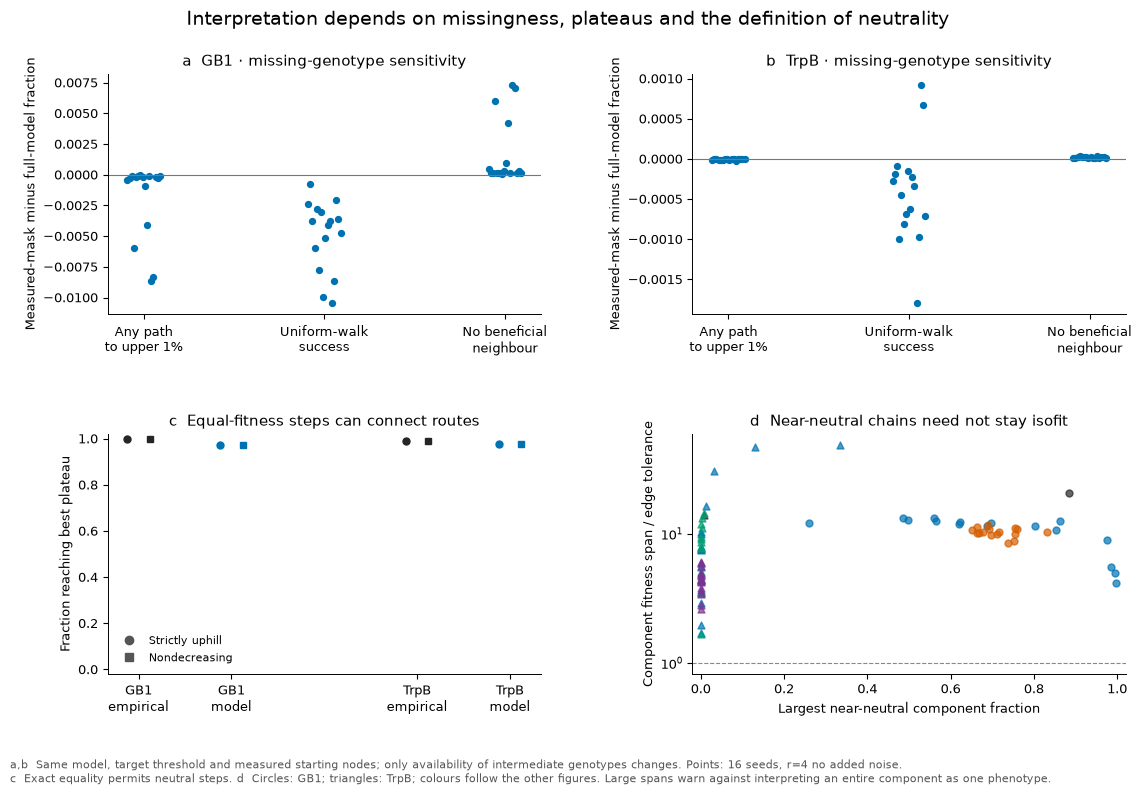

In [8]:
plots.diagnostics(frames)

## Exact summaries and reproducibility

The empirical graph is one measured map. Synthetic medians and seed ranges
represent variation in this generator with fixed fitted parameters; they omit
measurement and parameter-estimation uncertainty. Adaptive walk simulations are
checked against exact dynamic-programming expectations. Every sampled walk
terminated before the step cap. Raw landscapes, endpoint samples, summaries and
input hashes are retained in the linked DVC bundle.

In [9]:
primary = frames['graph_summary'].query('relative_resolution == 0.001')
metrics = ['uniform_steps','greedy_steps','accessible_top','uniform_hit_top','greedy_hit_top',
           'accessible_best','uniform_hit_best','no_beneficial_fraction','neutral_edge_fraction',
           'all_largest_fraction','above_floor_largest_fraction']
display(primary.groupby(['protein','case'])[metrics].median())
display(frames['mask_sensitivity'].groupby(['protein','metric']).difference.agg(['min','median','max']))
for relative, expected in audit['manifest'].items():
    assert tools.sha(tools.DATA/relative) == expected, relative
print('Verified',len(audit['manifest']),'data artifact hashes; six figures exported as PNG and PDF.')

uniform_steps  greedy_steps  accessible_top  \
protein case                                                                    
GB1     empirical                      9.740395      4.089048        0.995949   
        r0_none                        9.185591      3.674005        0.968737   
        r4_none                        5.271779      2.171993        0.998333   
TrpB    empirical                      8.588703      3.468595        0.988104   
        r0_none                       10.352278      3.804241        1.000000   
        r4_independent_intrinsic       6.351534      2.674868        0.999252   
        r4_independent_observed        6.219606      2.589302        0.997911   
        r4_none                        6.368164      2.674107        0.999249   
        r4_shared_intrinsic            5.699727      2.606816        0.998859   
        r4_shared_observed             4.874795      1.946191        0.990451   

                                  uniform_hit_top  greedy_hit_top  \
protein case                                                        
GB1     empirical                        0.935385        0.926551   
        r0_none                          0.968737        0.968737   
        r4_none                          0.942396        0.942053   
TrpB    empirical                        0.649778        0.627133   
        r0_none                          1.000000        1.000000   
        r4_independent_intrinsic         0.956556        0.954820   
        r4_independent_observed          0.934642        0.924860   
        r4_none                          0.956523        0.954820   
        r4_shared_intrinsic              0.951948        0.949362   
        r4_shared_observed               0.701167        0.787041   

                                  accessible_best  uniform_hit_best  \
protein case                                                          
GB1     empirical                        0.995574          0.261047   
        r0_none                          0.966086          0.948732   
        r4_none                          0.952755          0.003324   
TrpB    empirical                        0.987306          0.155092   
        r0_none                          1.000000          1.000000   
        r4_independent_intrinsic         0.975592          0.016701   
        r4_independent_observed          0.970370          0.023782   
        r4_none                          0.975539          0.016656   
        r4_shared_intrinsic              0.973188          0.013961   
        r4_shared_observed               0.927703          0.005151   

                                  no_beneficial_fraction  \
protein case                                               
GB1     empirical                               0.002504   
        r0_none                                 0.031270   
        r4_none                                 0.006066   
TrpB    empirical                               0.005140   
        r0_none                                 0.000006   
        r4_independent_intrinsic                0.002404   
        r4_independent_observed                 0.003645   
        r4_none                                 0.002407   
        r4_shared_intrinsic                     0.002916   
        r4_shared_observed                      0.010551   

                                  neutral_edge_fraction  all_largest_fraction  \
protein case                                                                    
GB1     empirical                              0.471922              0.883959   
        r0_none                                0.443212              0.704505   
        r4_none                                0.373138              0.691084   
TrpB    empirical                              0.007209              0.006793   
        r0_none                                0.008883              0.000151   
        r4_independent_intrinsic               0.022325              0.385040   
        r4

min    median       max
protein metric                                              
GB1     accessible_top         -0.008684 -0.000221 -0.000054
        no_beneficial_fraction  0.000087  0.000228  0.007311
        uniform_hit_top        -0.010453 -0.003941 -0.000778
        uniform_steps          -0.054390 -0.021849  0.005424
TrpB    accessible_top         -0.000025 -0.000006  0.000000
        no_beneficial_fraction  0.000006  0.000019  0.000038
        uniform_hit_top        -0.001796 -0.000399  0.000921
        uniform_steps          -0.018548 -0.003142  0.010027

Verified 402 data artifact hashes; six figures exported as PNG and PDF.


## Interpretation and literature

See `../analysis.md` for the figure-led interpretation of this execution. The
important scientific distinctions are route existence versus walk success,
relative versus absolute fitness, and operational near-neutral connectivity
versus a truly conserved biological phenotype. This is a four-site empirical
comparison, not evidence for statistical invariance with arbitrary length.

- [Wu et al. (2016), *Adaptation in protein fitness landscapes is facilitated by indirect paths*](https://doi.org/10.7554/eLife.16965).
- [Johnston et al. (2024), *A combinatorially complete epistatic fitness landscape in an enzyme active site*](https://doi.org/10.1073/pnas.2400439121).

No new RUN, RES or CLAIM is created and no scientific success gate is imposed.